# What drives flight delays from New York airports?

**Question.** Which factors (time of day, airline, weather, season) are associated with
longer departure and arrival delays for flights leaving New York City?

In [1]:
%load_ext autoreload
%autoreload 2
    
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
    
from src.flights import load, add_features, mean_by, plot_ranking, C1, C2, GRAY

plt.rcParams.update({"figure.dpi": 110})
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [2]:
flights = add_features(load("flights.csv.zip"))
airlines = load("airlines.csv")
weather = load("weather.csv")
print(f"{len(flights):,} flights · {flights["cancelled"].mean():.1%} cancelled")

336,776 flights · 2.5% cancelled


## Data

[nycflights](https://github.com/tidyverse/nycflights13) contains all domestic flights that departed in 2013 from New York City's airports: JFK, LaGuardia and Newark. There are tables of airlines and hourly weather at each origin airport as well. About 2.5% of flights were cancelled; delays are measured in minutes and negative values mean early departures or arrivals.

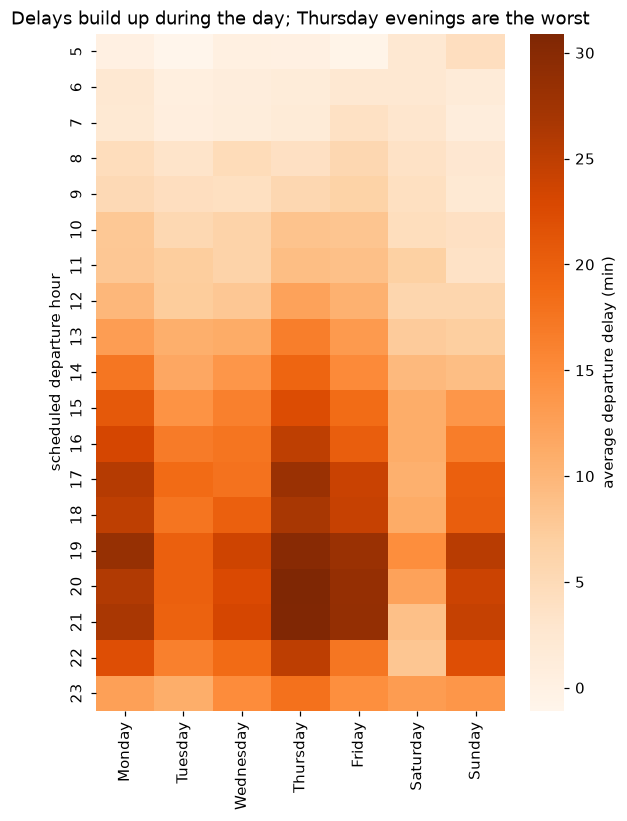

In [3]:
heat = (flights[flights["hour"] >= 5]
        .pivot_table(index="hour", columns="weekday", values="dep_delay", aggfunc="mean")
        [DAYS]
       )

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(heat, cmap="Oranges", cbar_kws={"label": "average departure delay (min)"}, ax=ax)
ax.set(title="Delays build up during the day; Thursday evenings are the worst",
       xlabel="",
       ylabel="scheduled departure hour"
      )
ax.grid(False)
fig.savefig("../figures/delays_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

### Analysis

**Finding 1 — Delays build up during the day.** Morning departures leave almost on
time every day of the week, but average delays grow steadily towards the evening,
peaking on Thursdays at around 8 p.m. (≈31 minutes). The likely mechanism is
knock-on delay: the same aircraft flies several legs a day, so an early delay is
carried into every later flight, while congestion at the airport also builds up.
Saturdays stay calm even in the evening, probably because there is less (business)
traffic, and delays rise again on Sunday evenings with weekend return trips.

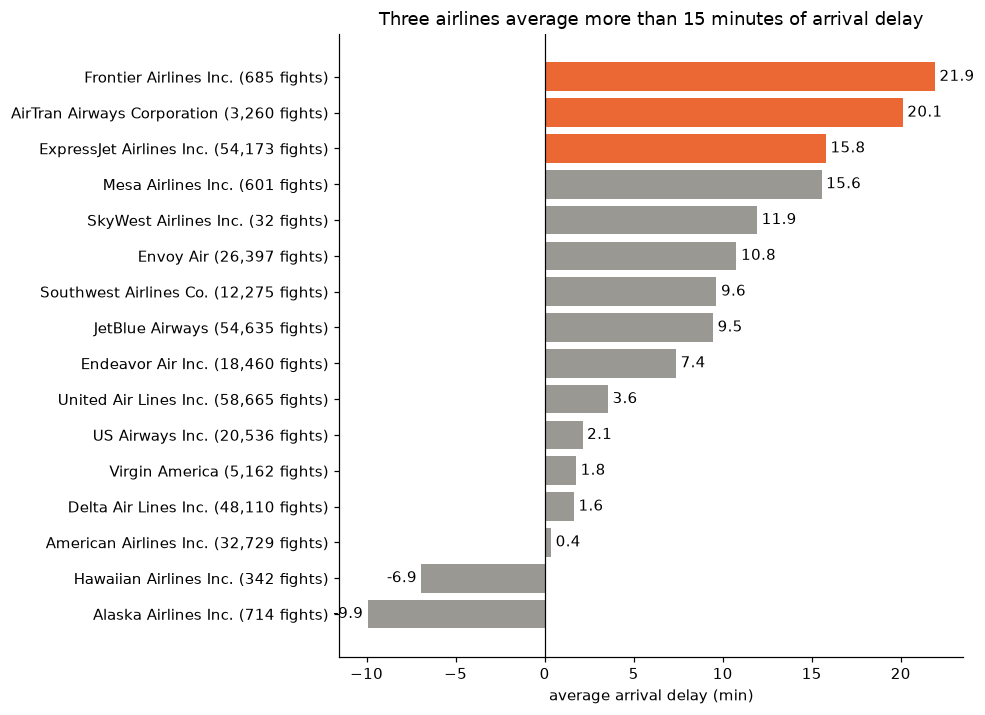

In [4]:
named = flights.merge(airlines, on="carrier", how="left")
airline_stats = mean_by(named, "name", "arr_delay")

labels = [f"{name} ({n:,} fights)" for name, n in zip(airline_stats.index, airline_stats["n"])]
ranking = pd.Series(airline_stats["mean"].values, index=labels)

ax = plot_ranking(ranking,
                  title="Three airlines average more than 15 minutes of arrival delay",
                  xlabel="average arrival delay (min)" 
                 )
ax.axvline(0, color="black", lw=0.8)
plt.show()

### Analysis

**Finding 2 — Airlines differ widely, but sample size matters.** Frontier, AirTran and
ExpressJet arrive more than 15 minutes late on average, over twice the mean across
all New York flights (≈7 minutes). ExpressJet carries the most weight: with over
50,000 flights a year, its delays affect far more passengers than any other airline's.
Frontier tops the ranking, but with only about 700 flights its average is much less
reliable: a few bad days can move it substantially. At the other end, Alaska and
Hawaiian arrive early on average, again on small samples and on long routes where
lost time can be recovered in the air.

In [5]:
fw = (flights.merge(weather.drop(columns=["year", "month", "day", "hour"]),
                                 on=["origin", "time_hour"], how="left")
             .dropna(subset=["precip"]))
fw["rain"] = fw["precip"] > 0

july_evening = fw[(fw["month"] == 7) & (fw["hour"].between(15, 20))]

comparison = pd.DataFrame({
    "All flights": fw.groupby("rain")["dep_delay"].mean(),
    "July, 3-8 p.m.": july_evening.groupby("rain")["dep_delay"].mean(),
}).rename(index={False: "no rain", True: "rain"})
comparison

,All flights,"July, 3-8 p.m."
rain,,
no rain,11.374509,35.113828
rain,30.927725,68.486994


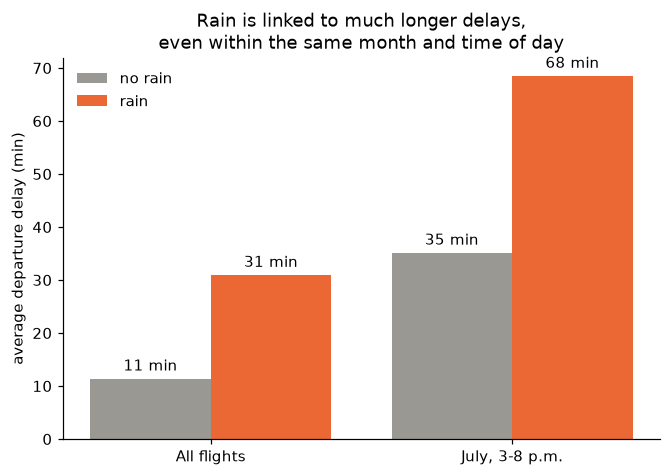

In [6]:
x = np.arange(len(comparison.columns))
w = 0.4

fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x - w/2, comparison.loc["no rain"], w, color=GRAY, label="no rain")
b2 = ax.bar(x + w/2, comparison.loc["rain"], w, color=C2, label="rain")
ax.bar_label(b1, fmt="%.0f min", padding=3)
ax.bar_label(b2, fmt="%.0f min", padding=3)
ax.set_xticks(x, comparison.columns)
ax.set(title="Rain is linked to much longer delays,\neven within the same month and time of day",
       ylabel="average departure delay (min)"
      )
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False)
plt.show()

### Analysis

**Finding 3 — Rain is linked to much longer delays, even comparing like with like.**
Across all flights, departures during rain are delayed about 31 minutes on average,
almost three times more than in dry conditions (11 minutes). Part of that gap is
confounding: rain is more frequent in months and hours that are already congested.
Comparing within the same month and time of day (July, 3–8 p.m.), delays without rain
are already 35 minutes, three times the yearly figure, yet rain still nearly doubles
them, to 68 minutes. In absolute terms the effect is even larger at peak times (+33
minutes, against +20 overall), which suggests that rain and congestion reinforce
each other. Caveats: the 734 rainy flights in this subgroup come from only 11 days,
so the evidence rests on a handful of weather episodes, and "rain" also includes
thunderstorms, which may be what actually halts operations.

## Limitations

- **Associations, not causal effects.** This is observational data. The weather
  analysis controls for month and time of day, but other factors (airport, airline,
  destination weather) could still explain part of the differences.
- **Missing outcomes.** Cancelled (≈2.5%) and diverted flights have no arrival delay
  and are excluded from the averages, so the figures understate the real disruption,
  especially on bad-weather days.
- **Small samples.** Some airlines operate only a few hundred flights, and the
  rainy-evening comparison rests on 11 days of rain, so those estimates are uncertain.
- **Scope.** One year (2013), one city and departures only. Patterns may have changed
  since then; some of these airlines no longer exist.

## Next steps

- **Test the knock-on hypothesis directly.** Use each aircraft's tail number
  (`tailnum`) to follow its flights through the day and measure how much of a delay
  is inherited from its previous flight.
- **Estimate the weather effect with more controls**, for example a regression that
  includes month, hour, airport, airline and destination weather at the same time.
- **Predict delays.** Train a model that predicts whether a flight will leave more
  than 15 minutes late from information known in advance (schedule, airline,
  weather forecast), validated on later months than those used for training.